In [1]:
 # ============================================================
#Task A 
# ============================================================

from __future__ import annotations

import os

# Disable the Albumentations internet version-check warning.
# This must be set before importing albumentations.
os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"

import hashlib
import importlib
import json
import random
import shutil
import sys

from collections import defaultdict
from pathlib import Path

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from IPython.display import Markdown, display
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from skimage.metrics import structural_similarity as ssim


# ============================================================
# Reproducibility
# ============================================================

SEED = 42
IMAGE_SIZE = 256
VALIDATION_COUNT = 314

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
cv2.setRNGSeed(SEED)


# ============================================================
# Input and output paths
# ============================================================

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working/NB0_outputs")

SPLIT_DIR = OUTPUT_ROOT / "splits"
ENCODED_MASK_DIR = OUTPUT_ROOT / "encoded_masks"
METADATA_DIR = OUTPUT_ROOT / "metadata"
COMMON_DIR = OUTPUT_ROOT / "common"


# Remove output from an earlier incomplete run.
if OUTPUT_ROOT.exists():
    shutil.rmtree(OUTPUT_ROOT)


for folder in [
    SPLIT_DIR,
    ENCODED_MASK_DIR / "training",
    ENCODED_MASK_DIR / "testing",
    METADATA_DIR,
    COMMON_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)


# ============================================================
# Class and original-mask definitions
# ============================================================

CLASS_NAMES = {
    0: "background",
    1: "landing_site",
}

# Original masks are RGB.
ORIGINAL_RGB_TO_CLASS = {
    (0, 0, 0): 0,
    (255, 255, 255): 1,
}

# Used only for notebook visualization.
CLASS_COLORS = {
    0: (0, 0, 0),
    1: (255, 0, 0),
}

ALLOWED_RGB_COLORS = set(ORIGINAL_RGB_TO_CLASS)


# ============================================================
# Automatically locate the dataset
# ============================================================

def find_dataset_root(input_root: Path) -> Path:
    candidates = set()

    for training_directory in input_root.rglob("training"):
        candidate_root = training_directory.parent

        required_directories = [
            candidate_root / "training" / "images",
            candidate_root / "training" / "masks",
            candidate_root / "testing" / "images",
            candidate_root / "testing" / "masks",
        ]

        if all(path.is_dir() for path in required_directories):
            candidates.add(candidate_root)

    if not candidates:
        raise FileNotFoundError(
            "Could not find the following folders under /kaggle/input:\n"
            "training/images\n"
            "training/masks\n"
            "testing/images\n"
            "testing/masks"
        )

    candidates = sorted(
        candidates,
        key=lambda path: (
            "moroccan" not in str(path).lower(),
            len(str(path)),
            str(path),
        ),
    )

    return candidates[0]


DATA_ROOT = find_dataset_root(INPUT_ROOT)


print("Dataset root:", DATA_ROOT)
print("Output root:", OUTPUT_ROOT)
print("Seed:", SEED)

print("\nOriginal RGB mask mapping:")
print("Black (0, 0, 0)       -> background, class 0")
print("White (255, 255, 255) -> landing_site, class 1")





Dataset root: /kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset
Output root: /kaggle/working/NB0_outputs
Seed: 42

Original RGB mask mapping:
Black (0, 0, 0)       -> background, class 0
White (255, 255, 255) -> landing_site, class 1


In [2]:
def collect_pngs(folder: Path) -> dict[str, Path]:
    """Return PNG files indexed by filename stem."""

    return {
        path.stem: path
        for path in folder.glob("*.png")
        if path.is_file()
    }


pair_rows = []
unmatched_rows = []


for source_partition in ["training", "testing"]:
    image_directory = DATA_ROOT / source_partition / "images"
    mask_directory = DATA_ROOT / source_partition / "masks"

    image_map = collect_pngs(image_directory)
    mask_map = collect_pngs(mask_directory)

    images_without_masks = sorted(
        set(image_map) - set(mask_map)
    )

    masks_without_images = sorted(
        set(mask_map) - set(image_map)
    )

    unmatched_rows.append(
        {
            "source_partition": source_partition,
            "image_count": len(image_map),
            "mask_count": len(mask_map),
            "images_without_masks": len(images_without_masks),
            "masks_without_images": len(masks_without_images),
        }
    )

    matched_stems = sorted(
        set(image_map).intersection(mask_map)
    )

    for stem in matched_stems:
        image_path = image_map[stem]
        mask_path = mask_map[stem]

        pair_rows.append(
            {
                # Partition prefix prevents ID collisions.
                "image_id": f"{source_partition}_{stem}",
                "file_stem": stem,
                "source_partition": source_partition,
                "image_path": image_path,
                "mask_path": mask_path,

                # Portable relative paths.
                "image_relpath": image_path.relative_to(
                    DATA_ROOT
                ).as_posix(),

                "encoded_mask_relpath": (
                    Path("encoded_masks")
                    / source_partition
                    / f"{stem}.png"
                ).as_posix(),
            }
        )


pairs_df = (
    pd.DataFrame(pair_rows)
    .sort_values(
        ["source_partition", "file_stem"]
    )
    .reset_index(drop=True)
)

unmatched_df = pd.DataFrame(unmatched_rows)


display(unmatched_df)

print("Matched image-mask pairs:", len(pairs_df))
print("Unique image IDs:", pairs_df["image_id"].nunique())


unmatched_problem_count = int(
    unmatched_df[
        [
            "images_without_masks",
            "masks_without_images",
        ]
    ].to_numpy().sum()
)


if unmatched_problem_count != 0:
    raise RuntimeError(
        "Images without masks or masks without images were found."
    )


if len(pairs_df) != 2090:
    raise RuntimeError(
        f"Expected 2,090 image-mask pairs, but found {len(pairs_df)}."
    )


if not pairs_df["image_id"].is_unique:
    raise RuntimeError(
        "The generated image_id values are not unique."
    )


print("Image-mask inventory check passed.")

,source_partition,image_count,mask_count,images_without_masks,masks_without_images
0,training,1730,1730,0,0
1,testing,360,360,0,0


Matched image-mask pairs: 2090
Unique image IDs: 2090
Image-mask inventory check passed.


In [3]:
def file_sha256(
    path: Path,
    chunk_size: int = 1024 * 1024,
) -> str:
    """Calculate SHA-256 from file bytes."""

    digest = hashlib.sha256()

    with path.open("rb") as file:
        while chunk := file.read(chunk_size):
            digest.update(chunk)

    return digest.hexdigest()


def array_sha256(array: np.ndarray) -> str:
    """Calculate SHA-256 from decoded pixel values."""

    contiguous_array = np.ascontiguousarray(array)

    return hashlib.sha256(
        contiguous_array.tobytes()
    ).hexdigest()


def calculate_phash(
    rgb_image: np.ndarray,
) -> int:
    """Calculate a 64-bit perceptual hash."""

    grayscale = cv2.cvtColor(
        rgb_image,
        cv2.COLOR_RGB2GRAY,
    )

    resized = cv2.resize(
        grayscale,
        (32, 32),
        interpolation=cv2.INTER_AREA,
    )

    dct_values = cv2.dct(
        resized.astype(np.float32)
    )[:8, :8]

    median_value = np.median(
        dct_values.flatten()[1:]
    )

    bits = (
        dct_values > median_value
    ).flatten()

    hash_value = 0

    for bit in bits:
        hash_value = (
            hash_value << 1
        ) | int(bit)

    return hash_value


def encode_rgb_mask(
    mask_rgb: np.ndarray,
) -> np.ndarray:
    """
    Convert the original RGB mask into:

    0 = background
    1 = landing_site
    """

    background_pixels = np.all(
        mask_rgb == (0, 0, 0),
        axis=-1,
    )

    landing_site_pixels = np.all(
        mask_rgb == (255, 255, 255),
        axis=-1,
    )

    known_pixels = (
        background_pixels
        | landing_site_pixels
    )

    if not np.all(known_pixels):
        unknown_colors = np.unique(
            mask_rgb[~known_pixels],
            axis=0,
        ).tolist()

        raise ValueError(
            f"Unknown mask colours: {unknown_colors}"
        )

    encoded_mask = np.zeros(
        mask_rgb.shape[:2],
        dtype=np.uint8,
    )

    encoded_mask[
        landing_site_pixels
    ] = 1

    return encoded_mask


quality_rows = []

# Used later for near-duplicate and crop investigation.
gray_thumbnails = {}
histogram_features = {}


for row in pairs_df.itertuples(index=False):
    record = {
        "image_id": row.image_id,
        "image_corrupted": False,
        "mask_corrupted": False,
        "image_error": "",
        "mask_error": "",
        "unknown_mask_colors": "",
    }

    image_rgb = None
    mask_rgb = None

    # --------------------------------------------------------
    # Image checks
    # --------------------------------------------------------

    try:
        with Image.open(row.image_path) as image_file:
            image_file.verify()

        with Image.open(row.image_path) as image_file:
            image_rgb = np.asarray(
                image_file.convert("RGB"),
                dtype=np.uint8,
            )

        record["image_height"] = int(
            image_rgb.shape[0]
        )

        record["image_width"] = int(
            image_rgb.shape[1]
        )

        record["image_file_sha256"] = (
            file_sha256(row.image_path)
        )

        record["image_pixel_sha256"] = (
            array_sha256(image_rgb)
        )

        record["phash"] = calculate_phash(
            image_rgb
        )

        grayscale = cv2.cvtColor(
            image_rgb,
            cv2.COLOR_RGB2GRAY,
        )

        gray_thumbnails[row.image_id] = (
            cv2.resize(
                grayscale,
                (64, 64),
                interpolation=cv2.INTER_AREA,
            )
        )

        hsv_image = cv2.cvtColor(
            image_rgb,
            cv2.COLOR_RGB2HSV,
        )

        histogram = cv2.calcHist(
            [hsv_image],
            [0, 1],
            None,
            [16, 16],
            [0, 180, 0, 256],
        )

        histogram_features[row.image_id] = (
            cv2.normalize(
                histogram,
                histogram,
            )
            .flatten()
            .astype(np.float32)
        )

    except Exception as error:
        record["image_corrupted"] = True
        record["image_error"] = repr(error)

    # --------------------------------------------------------
    # Original RGB mask checks
    # --------------------------------------------------------

    try:
        with Image.open(row.mask_path) as mask_file:
            record["mask_mode"] = mask_file.mode
            mask_file.verify()

        with Image.open(row.mask_path) as mask_file:
            raw_mask = np.asarray(mask_file)

        if (
            raw_mask.ndim != 3
            or raw_mask.shape[2] < 3
        ):
            raise ValueError(
                "Expected an RGB mask, but received "
                f"shape {raw_mask.shape}."
            )

        mask_rgb = raw_mask[
            :, :, :3
        ].astype(np.uint8)

        record["mask_height"] = int(
            mask_rgb.shape[0]
        )

        record["mask_width"] = int(
            mask_rgb.shape[1]
        )

        record["mask_file_sha256"] = (
            file_sha256(row.mask_path)
        )

        record["mask_pixel_sha256"] = (
            array_sha256(mask_rgb)
        )

        colors, counts = np.unique(
            mask_rgb.reshape(-1, 3),
            axis=0,
            return_counts=True,
        )

        color_counts = {
            tuple(
                int(channel)
                for channel in color
            ): int(count)
            for color, count in zip(
                colors,
                counts,
            )
        }

        unknown_colors = sorted(
            set(color_counts)
            - ALLOWED_RGB_COLORS
        )

        record["unknown_mask_colors"] = (
            "; ".join(
                str(color)
                for color in unknown_colors
            )
        )

        record["unknown_mask_color_count"] = int(
            sum(
                color_counts[color]
                for color in unknown_colors
            )
        )

        record["background_pixels"] = int(
            color_counts.get(
                (0, 0, 0),
                0,
            )
        )

        record["landing_site_pixels"] = int(
            color_counts.get(
                (255, 255, 255),
                0,
            )
        )

        record["total_pixels"] = int(
            mask_rgb.shape[0]
            * mask_rgb.shape[1]
        )

        record["has_landing_site"] = (
            record["landing_site_pixels"] > 0
        )

        record["landing_site_fraction"] = (
            record["landing_site_pixels"]
            / record["total_pixels"]
        )

    except Exception as error:
        record["mask_corrupted"] = True
        record["mask_error"] = repr(error)

    record["dimension_match"] = (
        image_rgb is not None
        and mask_rgb is not None
        and image_rgb.shape[:2]
        == mask_rgb.shape[:2]
    )

    quality_rows.append(record)


quality_df = pd.DataFrame(quality_rows)

pairs_df = pairs_df.merge(
    quality_df,
    on="image_id",
    how="left",
)

pairs_df["aspect_ratio"] = (
    pairs_df["image_width"]
    / pairs_df["image_height"]
)


quality_summary = pd.DataFrame(
    [
        [
            "Corrupted images",
            int(
                pairs_df[
                    "image_corrupted"
                ].sum()
            ),
        ],
        [
            "Corrupted masks",
            int(
                pairs_df[
                    "mask_corrupted"
                ].sum()
            ),
        ],
        [
            "Images without masks",
            int(
                unmatched_df[
                    "images_without_masks"
                ].sum()
            ),
        ],
        [
            "Masks without images",
            int(
                unmatched_df[
                    "masks_without_images"
                ].sum()
            ),
        ],
        [
            "Image-mask dimension mismatches",
            int(
                (
                    ~pairs_df[
                        "dimension_match"
                    ]
                ).sum()
            ),
        ],
        [
            "Masks not stored as RGB",
            int(
                (
                    pairs_df["mask_mode"]
                    != "RGB"
                ).sum()
            ),
        ],
        [
            "Masks with unknown colours",
            int(
                (
                    pairs_df[
                        "unknown_mask_color_count"
                    ] > 0
                ).sum()
            ),
        ],
        [
            "Images not 256x256",
            int(
                (
                    (
                        pairs_df["image_width"]
                        != IMAGE_SIZE
                    )
                    |
                    (
                        pairs_df["image_height"]
                        != IMAGE_SIZE
                    )
                ).sum()
            ),
        ],
        [
            "Masks not 256x256",
            int(
                (
                    (
                        pairs_df["mask_width"]
                        != IMAGE_SIZE
                    )
                    |
                    (
                        pairs_df["mask_height"]
                        != IMAGE_SIZE
                    )
                ).sum()
            ),
        ],
    ],
    columns=[
        "check",
        "problem_count",
    ],
)


display(quality_summary)


if quality_summary[
    "problem_count"
].sum() != 0:

    problem_rows = pairs_df[
        pairs_df["image_corrupted"]
        | pairs_df["mask_corrupted"]
        | ~pairs_df["dimension_match"]
        | (
            pairs_df["mask_mode"]
            != "RGB"
        )
        | (
            pairs_df[
                "unknown_mask_color_count"
            ] > 0
        )
        | (
            pairs_df["image_width"]
            != IMAGE_SIZE
        )
        | (
            pairs_df["image_height"]
            != IMAGE_SIZE
        )
        | (
            pairs_df["mask_width"]
            != IMAGE_SIZE
        )
        | (
            pairs_df["mask_height"]
            != IMAGE_SIZE
        )
    ]

    display(
        problem_rows[
            [
                "image_id",
                "image_error",
                "mask_error",
                "mask_mode",
                "unknown_mask_colors",
                "dimension_match",
            ]
        ]
    )

    raise RuntimeError(
        "One or more file-quality checks failed."
    )


# ============================================================
# Export encoded masks
# ============================================================

for row in pairs_df.itertuples(index=False):
    with Image.open(row.mask_path) as mask_file:
        mask_rgb = np.asarray(
            mask_file
        )[:, :, :3].astype(np.uint8)

    encoded_mask = encode_rgb_mask(
        mask_rgb
    )

    output_mask_path = (
        OUTPUT_ROOT
        / row.encoded_mask_relpath
    )

    Image.fromarray(
        encoded_mask
    ).save(output_mask_path)


print("All file-quality checks passed.")

print(
    "Encoded masks were saved as single-channel "
    "PNG files containing only 0 and 1."
)

,check,problem_count
0,Corrupted images,0
1,Corrupted masks,0
2,Images without masks,0
3,Masks without images,0
4,Image-mask dimension mismatches,0
5,Masks not stored as RGB,0
6,Masks with unknown colours,0
7,Images not 256x256,0
8,Masks not 256x256,0


All file-quality checks passed.
Encoded masks were saved as single-channel PNG files containing only 0 and 1.


,item,value
0,Image-mask pairs,2090
1,Classes,2
2,Uniform resolution,256x256
3,Landing-site-positive images,1570
4,Background-only images,520
5,Background/landing-site pixel ratio,2.31:1
6,Imbalance severity,moderate


,class_id,class_name,pixel_count,pixel_percent
0,0,background,95625431,69.81475
1,1,landing_site,41344809,30.18525


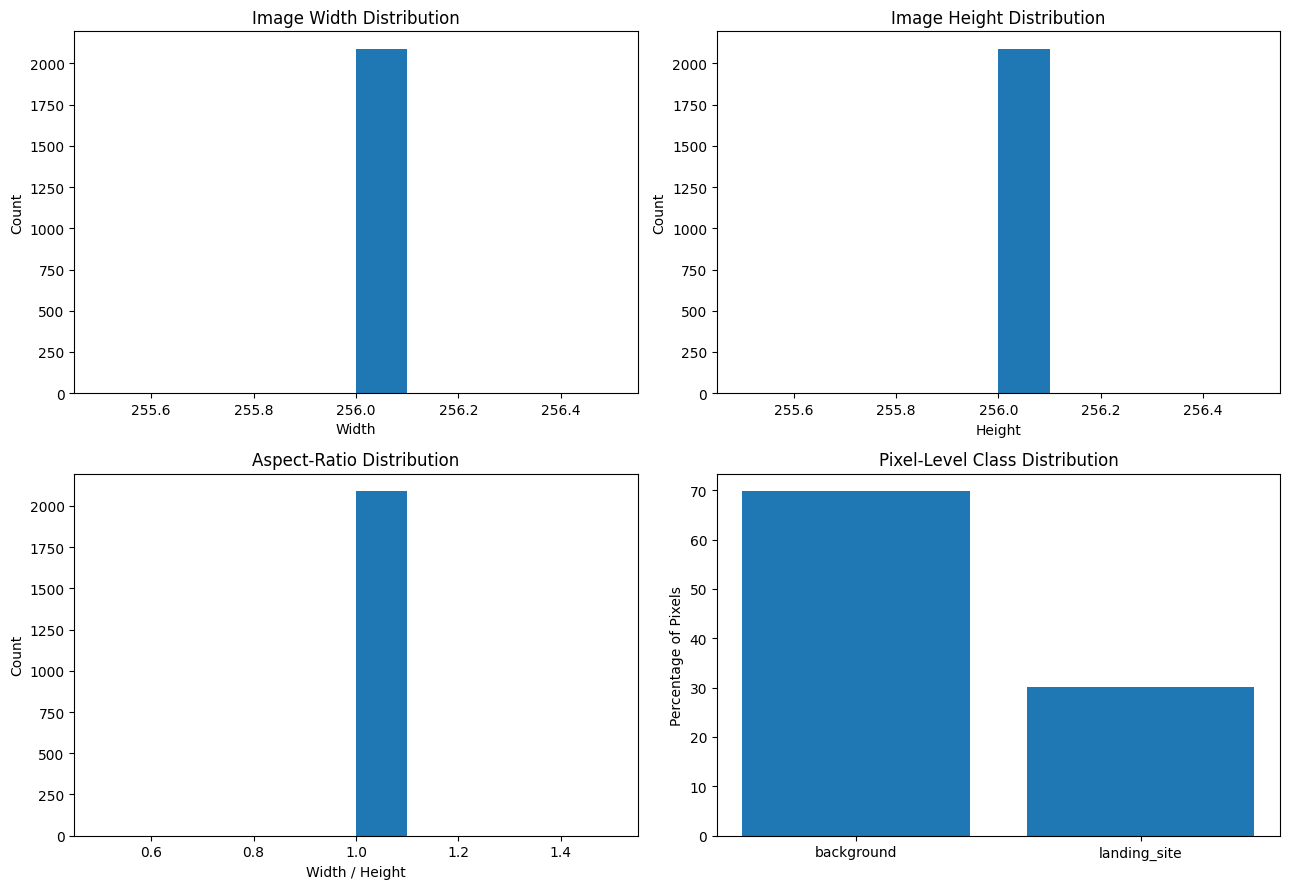

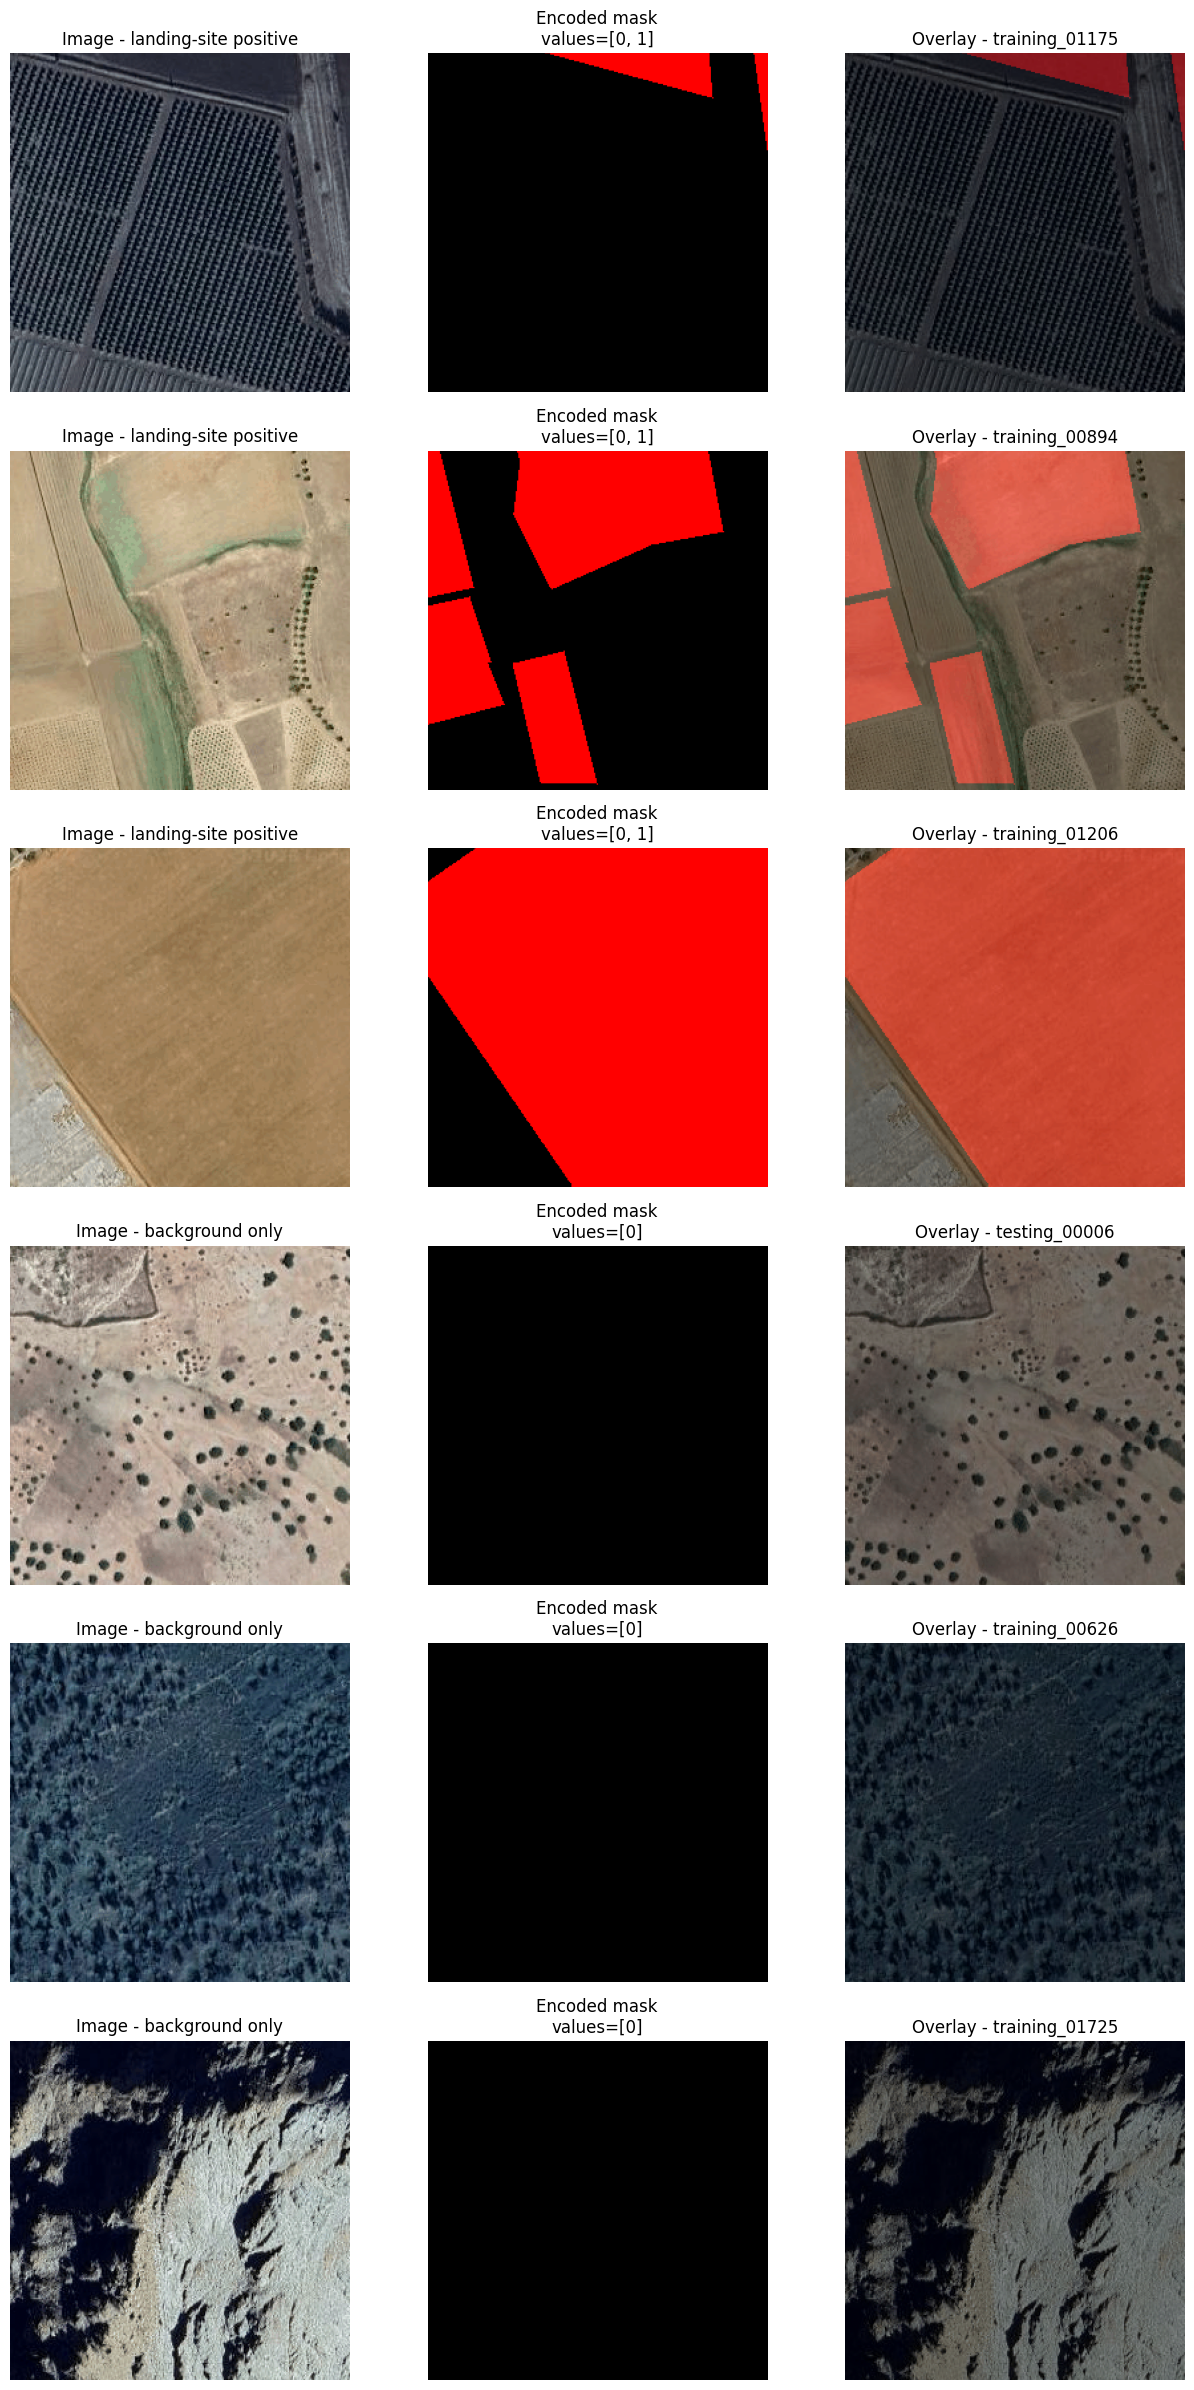


### EDA discussion

- The dataset contains **2,090 image-mask pairs**.
- There are **two semantic classes**: background, class 0, and
  landing_site, class 1.
- The original masks are RGB PNG masks. Black represents background
  and white represents the landing-site class.
- Every image and mask has uniform resolution
  **256x256** with aspect ratio 1.0.
- There are **1,570 landing-site-positive
  images** and **520 background-only images**.
- Background pixels account for
  **69.81%** of pixels.
- Landing-site pixels account for
  **30.19%** of pixels.
- The background-to-landing-site ratio is approximately
  **2.31:1**, indicating **moderate
  pixel-level imbalance**.
- Overall pixel accuracy may be misleading because the dominant
  background class can produce a high score.
- Weighted cross-entropy combined with Dice loss, or focal loss,
  should therefore be considered in the model notebooks.
- Class weights are calculated from **training pixels only** after
  splitting the data.


In [4]:
def colorize_mask(
    mask: np.ndarray,
) -> np.ndarray:
    """Convert class-index mask to RGB colours."""

    colored_mask = np.zeros(
        (*mask.shape, 3),
        dtype=np.uint8,
    )

    for class_id, color in (
        CLASS_COLORS.items()
    ):
        colored_mask[
            mask == class_id
        ] = color

    return colored_mask


def overlay_image_mask(
    image: np.ndarray,
    mask: np.ndarray,
    alpha: float = 0.45,
) -> np.ndarray:
    """Create an image-mask overlay."""

    colored_mask = colorize_mask(
        mask
    )

    overlay = (
        (1 - alpha)
        * image.astype(np.float32)
        + alpha
        * colored_mask.astype(np.float32)
    )

    return np.clip(
        overlay,
        0,
        255,
    ).astype(np.uint8)


# ============================================================
# Full-dataset EDA statistics
# ============================================================

background_pixels = int(
    pairs_df[
        "background_pixels"
    ].sum()
)

landing_site_pixels = int(
    pairs_df[
        "landing_site_pixels"
    ].sum()
)

total_pixels = (
    background_pixels
    + landing_site_pixels
)


pixel_distribution_df = pd.DataFrame(
    {
        "class_id": [0, 1],

        "class_name": [
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],

        "pixel_count": [
            background_pixels,
            landing_site_pixels,
        ],

        "pixel_percent": [
            100
            * background_pixels
            / total_pixels,

            100
            * landing_site_pixels
            / total_pixels,
        ],
    }
)


landing_site_positive_count = int(
    pairs_df[
        "has_landing_site"
    ].sum()
)

background_only_count = int(
    (
        ~pairs_df[
            "has_landing_site"
        ]
    ).sum()
)


imbalance_ratio = (
    background_pixels
    / landing_site_pixels
    if landing_site_pixels > 0
    else float("inf")
)


if imbalance_ratio < 1.5:
    imbalance_severity = "mild"

elif imbalance_ratio < 4:
    imbalance_severity = "moderate"

else:
    imbalance_severity = "severe"


eda_summary = pd.DataFrame(
    [
        [
            "Image-mask pairs",
            len(pairs_df),
        ],
        [
            "Classes",
            2,
        ],
        [
            "Uniform resolution",
            f"{IMAGE_SIZE}x{IMAGE_SIZE}",
        ],
        [
            "Landing-site-positive images",
            landing_site_positive_count,
        ],
        [
            "Background-only images",
            background_only_count,
        ],
        [
            "Background/landing-site pixel ratio",
            f"{imbalance_ratio:.2f}:1",
        ],
        [
            "Imbalance severity",
            imbalance_severity,
        ],
    ],
    columns=[
        "item",
        "value",
    ],
)


display(eda_summary)
display(pixel_distribution_df)


# ============================================================
# EDA plots
# ============================================================

figure, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9),
)


axes[0, 0].hist(
    pairs_df["image_width"],
    bins=10,
)

axes[0, 0].set_title(
    "Image Width Distribution"
)

axes[0, 0].set_xlabel(
    "Width"
)

axes[0, 0].set_ylabel(
    "Count"
)


axes[0, 1].hist(
    pairs_df["image_height"],
    bins=10,
)

axes[0, 1].set_title(
    "Image Height Distribution"
)

axes[0, 1].set_xlabel(
    "Height"
)

axes[0, 1].set_ylabel(
    "Count"
)


axes[1, 0].hist(
    pairs_df["aspect_ratio"],
    bins=10,
)

axes[1, 0].set_title(
    "Aspect-Ratio Distribution"
)

axes[1, 0].set_xlabel(
    "Width / Height"
)

axes[1, 0].set_ylabel(
    "Count"
)


axes[1, 1].bar(
    pixel_distribution_df[
        "class_name"
    ],
    pixel_distribution_df[
        "pixel_percent"
    ],
)

axes[1, 1].set_title(
    "Pixel-Level Class Distribution"
)

axes[1, 1].set_ylabel(
    "Percentage of Pixels"
)


plt.tight_layout()
plt.show()


# ============================================================
# Representative examples for both mask categories
# ============================================================

def select_quantile_examples(
    dataframe: pd.DataFrame,
    value_column: str,
    quantiles: list[float],
) -> pd.DataFrame:
    """Select samples across a numeric distribution."""

    ordered_dataframe = (
        dataframe
        .sort_values(
            value_column
        )
        .reset_index(drop=True)
    )

    selected_indices = sorted(
        {
            int(
                round(
                    quantile
                    * (
                        len(
                            ordered_dataframe
                        ) - 1
                    )
                )
            )
            for quantile in quantiles
        }
    )

    return ordered_dataframe.iloc[
        selected_indices
    ]


positive_examples = (
    select_quantile_examples(
        pairs_df[
            pairs_df[
                "has_landing_site"
            ]
        ],
        "landing_site_fraction",
        [0.10, 0.50, 0.90],
    )
    .assign(
        example_type=(
            "landing-site positive"
        )
    )
)


background_pool = (
    pairs_df[
        ~pairs_df[
            "has_landing_site"
        ]
    ]
    .sort_values("image_id")
    .reset_index(drop=True)
)


if background_pool.empty:
    raise RuntimeError(
        "No background-only masks were found."
    )


background_indices = np.linspace(
    0,
    len(background_pool) - 1,
    num=3,
    dtype=int,
)


background_examples = (
    background_pool.iloc[
        np.unique(
            background_indices
        )
    ]
    .assign(
        example_type=(
            "background only"
        )
    )
)


representative_df = pd.concat(
    [
        positive_examples,
        background_examples,
    ],
    ignore_index=True,
)


figure, axes = plt.subplots(
    len(representative_df),
    3,
    figsize=(
        13,
        4 * len(
            representative_df
        ),
    ),
)


for row_index, row in (
    representative_df.iterrows()
):
    with Image.open(
        row["image_path"]
    ) as image_file:
        image = np.asarray(
            image_file.convert("RGB"),
            dtype=np.uint8,
        )

    with Image.open(
        OUTPUT_ROOT
        / row[
            "encoded_mask_relpath"
        ]
    ) as mask_file:
        encoded_mask = np.asarray(
            mask_file,
            dtype=np.uint8,
        )

    axes[row_index, 0].imshow(
        image
    )

    axes[row_index, 0].set_title(
        f"Image - {row['example_type']}"
    )

    axes[row_index, 1].imshow(
        colorize_mask(
            encoded_mask
        )
    )

    axes[row_index, 1].set_title(
        "Encoded mask\n"
        f"values={np.unique(encoded_mask).tolist()}"
    )

    axes[row_index, 2].imshow(
        overlay_image_mask(
            image,
            encoded_mask,
        )
    )

    axes[row_index, 2].set_title(
        f"Overlay - {row['image_id']}"
    )

    for column_index in range(3):
        axes[
            row_index,
            column_index,
        ].axis("off")


plt.tight_layout()
plt.show()


# ============================================================
# Required EDA discussion
# ============================================================

display(
    Markdown(
        f"""
### EDA discussion

- The dataset contains **{len(pairs_df):,} image-mask pairs**.
- There are **two semantic classes**: background, class 0, and
  landing_site, class 1.
- The original masks are RGB PNG masks. Black represents background
  and white represents the landing-site class.
- Every image and mask has uniform resolution
  **{IMAGE_SIZE}x{IMAGE_SIZE}** with aspect ratio 1.0.
- There are **{landing_site_positive_count:,} landing-site-positive
  images** and **{background_only_count:,} background-only images**.
- Background pixels account for
  **{pixel_distribution_df.loc[0, "pixel_percent"]:.2f}%** of pixels.
- Landing-site pixels account for
  **{pixel_distribution_df.loc[1, "pixel_percent"]:.2f}%** of pixels.
- The background-to-landing-site ratio is approximately
  **{imbalance_ratio:.2f}:1**, indicating **{imbalance_severity}
  pixel-level imbalance**.
- Overall pixel accuracy may be misleading because the dominant
  background class can produce a high score.
- Weighted cross-entropy combined with Dice loss, or focal loss,
  should therefore be considered in the model notebooks.
- Class weights are calculated from **training pixels only** after
  splitting the data.
"""
    )
)

In [5]:


from collections import defaultdict
import hashlib

import cv2
import numpy as np
import pandas as pd

from IPython.display import Markdown, display
from sklearn.neighbors import NearestNeighbors
from skimage.metrics import structural_similarity as ssim


# ============================================================
# Check that Task A1-A3 were executed
# ============================================================

required_columns = [
    "image_id",
    "file_stem",
    "source_partition",
    "image_path",
    "image_file_sha256",
    "image_pixel_sha256",
    "mask_file_sha256",
    "phash",
]

missing_columns = [
    column
    for column in required_columns
    if column not in pairs_df.columns
]

if missing_columns:
    raise RuntimeError(
        "Run Task A1, A2 and A3 first. "
        f"Missing pairs_df columns: {missing_columns}"
    )


if "gray_thumbnails" not in globals():
    raise RuntimeError(
        "gray_thumbnails is missing. "
        "Run Task A3 again before running Task A4."
    )


if "histogram_features" not in globals():
    raise RuntimeError(
        "histogram_features is missing. "
        "Run Task A3 again before running Task A4."
    )


# ============================================================
# 1. Find exact duplicate groups
# ============================================================

def find_duplicate_groups(
    dataframe: pd.DataFrame,
    hash_column: str,
) -> pd.DataFrame:
    groups = (
        dataframe.groupby(hash_column)["image_id"]
        .agg(list)
        .reset_index(name="image_ids")
    )

    groups["count"] = (
        groups["image_ids"].str.len()
    )

    return (
        groups[
            groups["count"] > 1
        ]
        .reset_index(drop=True)
    )


exact_image_file_groups = find_duplicate_groups(
    pairs_df,
    "image_file_sha256",
)

exact_image_pixel_groups = find_duplicate_groups(
    pairs_df,
    "image_pixel_sha256",
)

exact_mask_file_groups = find_duplicate_groups(
    pairs_df,
    "mask_file_sha256",
)


print(
    "Exact image-file duplicate groups:",
    len(exact_image_file_groups),
)

print(
    "Exact decoded-image duplicate groups:",
    len(exact_image_pixel_groups),
)

print(
    "Exact mask-file duplicate groups:",
    len(exact_mask_file_groups),
)


# ============================================================
# 2. Near-duplicate detection using pHash and SSIM
# ============================================================

PHASH_THRESHOLD = 6
SSIM_THRESHOLD = 0.97


image_ids = (
    pairs_df["image_id"].tolist()
)

phash_values = (
    pairs_df["phash"]
    .astype(object)
    .tolist()
)

pixel_hash_lookup = (
    pairs_df
    .set_index("image_id")[
        "image_pixel_sha256"
    ]
    .to_dict()
)


near_duplicate_rows = []


for left_index in range(len(image_ids)):

    for right_index in range(
        left_index + 1,
        len(image_ids),
    ):
        phash_distance = (
            int(phash_values[left_index])
            ^ int(phash_values[right_index])
        ).bit_count()

        if phash_distance > PHASH_THRESHOLD:
            continue

        left_id = image_ids[left_index]
        right_id = image_ids[right_index]

        # Exact duplicates were already recorded.
        if (
            pixel_hash_lookup[left_id]
            == pixel_hash_lookup[right_id]
        ):
            continue

        similarity = ssim(
            gray_thumbnails[left_id],
            gray_thumbnails[right_id],
            data_range=255,
        )

        if similarity >= SSIM_THRESHOLD:
            near_duplicate_rows.append(
                {
                    "image_id_a": left_id,
                    "image_id_b": right_id,
                    "phash_distance": int(
                        phash_distance
                    ),
                    "ssim": float(similarity),
                }
            )


near_duplicate_df = pd.DataFrame(
    near_duplicate_rows,
    columns=[
        "image_id_a",
        "image_id_b",
        "phash_distance",
        "ssim",
    ],
)


print(
    "Near-duplicate image pairs:",
    len(near_duplicate_df),
)


# ============================================================
# 3. Build candidate pairs for crop/same-scene investigation
# ============================================================

histogram_matrix = np.vstack(
    [
        histogram_features[image_id]
        for image_id in image_ids
    ]
)


neighbour_model = NearestNeighbors(
    n_neighbors=min(
        6,
        len(image_ids),
    ),
    metric="cosine",
)

neighbour_model.fit(
    histogram_matrix
)


_, neighbour_indices = (
    neighbour_model.kneighbors(
        histogram_matrix
    )
)


candidate_pairs = set()


# Visually similar images based on HSV histogram.
for left_index, neighbours in enumerate(
    neighbour_indices
):
    for right_index in neighbours[1:]:
        candidate_pairs.add(
            tuple(
                sorted(
                    (
                        left_index,
                        int(right_index),
                    )
                )
            )
        )


# Nearby numeric filenames are also investigated.
for _, partition_df in pairs_df.groupby(
    "source_partition"
):
    numeric_index = {
        int(row.file_stem): int(row.Index)
        for row in partition_df.itertuples()
        if str(row.file_stem).isdigit()
    }

    for number, left_index in (
        numeric_index.items()
    ):
        for offset in (1, 2):
            right_index = numeric_index.get(
                number + offset
            )

            if right_index is not None:
                candidate_pairs.add(
                    tuple(
                        sorted(
                            (
                                left_index,
                                right_index,
                            )
                        )
                    )
                )


print(
    "Crop/same-scene candidate pairs:",
    len(candidate_pairs),
)


# ============================================================
# 4. Extract ORB features
# ============================================================

orb_detector = cv2.ORB_create(
    nfeatures=600,
    fastThreshold=10,
)


orb_features = {}


for row in pairs_df.itertuples(
    index=False
):
    grayscale_image = cv2.imread(
        str(row.image_path),
        cv2.IMREAD_GRAYSCALE,
    )

    if grayscale_image is None:
        raise RuntimeError(
            f"Could not read image: {row.image_path}"
        )

    keypoints, descriptors = (
        orb_detector.detectAndCompute(
            grayscale_image,
            None,
        )
    )

    orb_features[row.image_id] = (
        keypoints,
        descriptors,
    )


feature_matcher = cv2.BFMatcher(
    cv2.NORM_HAMMING,
    crossCheck=False,
)


MIN_GOOD_MATCHES = 35
MIN_HOMOGRAPHY_INLIERS = 25
MIN_INLIER_RATIO = 0.60
MIN_COVERAGE = 0.08


# ============================================================
# 5. Crop/same-scene relation functions
# ============================================================

def point_coverage(
    points: np.ndarray,
    width: int,
    height: int,
) -> float:
    if len(points) < 3:
        return 0.0

    hull = cv2.convexHull(
        points.astype(np.float32)
    )

    return float(
        cv2.contourArea(hull)
        / float(width * height)
    )


def investigate_crop_relation(
    left_id: str,
    right_id: str,
) -> dict | None:

    left_keypoints, left_descriptors = (
        orb_features[left_id]
    )

    right_keypoints, right_descriptors = (
        orb_features[right_id]
    )

    if (
        left_descriptors is None
        or right_descriptors is None
        or len(left_descriptors) < 2
        or len(right_descriptors) < 2
    ):
        return None

    raw_matches = feature_matcher.knnMatch(
        left_descriptors,
        right_descriptors,
        k=2,
    )

    good_matches = []

    for match_pair in raw_matches:

        if len(match_pair) != 2:
            continue

        first_match, second_match = (
            match_pair
        )

        if (
            first_match.distance
            < 0.70 * second_match.distance
        ):
            good_matches.append(
                first_match
            )

    if (
        len(good_matches)
        < MIN_GOOD_MATCHES
    ):
        return None

    left_points = np.float32(
        [
            left_keypoints[
                match.queryIdx
            ].pt
            for match in good_matches
        ]
    )

    right_points = np.float32(
        [
            right_keypoints[
                match.trainIdx
            ].pt
            for match in good_matches
        ]
    )

    _, inlier_mask = cv2.findHomography(
        left_points,
        right_points,
        cv2.RANSAC,
        4.0,
    )

    if inlier_mask is None:
        return None

    inlier_mask = (
        inlier_mask
        .ravel()
        .astype(bool)
    )

    inlier_count = int(
        inlier_mask.sum()
    )

    inlier_ratio = (
        inlier_count
        / len(good_matches)
    )

    left_coverage = point_coverage(
        left_points[inlier_mask],
        IMAGE_SIZE,
        IMAGE_SIZE,
    )

    right_coverage = point_coverage(
        right_points[inlier_mask],
        IMAGE_SIZE,
        IMAGE_SIZE,
    )

    if (
        inlier_count
        >= MIN_HOMOGRAPHY_INLIERS
        and inlier_ratio
        >= MIN_INLIER_RATIO
        and min(
            left_coverage,
            right_coverage,
        )
        >= MIN_COVERAGE
    ):
        return {
            "good_matches": int(
                len(good_matches)
            ),
            "homography_inliers": (
                inlier_count
            ),
            "inlier_ratio": float(
                inlier_ratio
            ),
            "left_coverage": float(
                left_coverage
            ),
            "right_coverage": float(
                right_coverage
            ),
        }

    return None


# ============================================================
# 6. Detect strong crop/same-scene relationships
# ============================================================

known_near_pairs = {
    tuple(
        sorted(
            (
                row.image_id_a,
                row.image_id_b,
            )
        )
    )
    for row in near_duplicate_df.itertuples(
        index=False
    )
}


crop_relation_rows = []


for left_index, right_index in sorted(
    candidate_pairs
):
    left_id = image_ids[left_index]
    right_id = image_ids[right_index]

    pair_key = tuple(
        sorted(
            (
                left_id,
                right_id,
            )
        )
    )

    if pair_key in known_near_pairs:
        continue

    if (
        pixel_hash_lookup[left_id]
        == pixel_hash_lookup[right_id]
    ):
        continue

    relationship = (
        investigate_crop_relation(
            left_id,
            right_id,
        )
    )

    if relationship is not None:
        crop_relation_rows.append(
            {
                "image_id_a": left_id,
                "image_id_b": right_id,
                **relationship,
            }
        )


crop_relation_df = pd.DataFrame(
    crop_relation_rows,
    columns=[
        "image_id_a",
        "image_id_b",
        "good_matches",
        "homography_inliers",
        "inlier_ratio",
        "left_coverage",
        "right_coverage",
    ],
)


print(
    "Strong crop/same-scene pairs:",
    len(crop_relation_df),
)


# ============================================================
# 7. Union-Find for connected relationship groups
# ============================================================

class UnionFind:

    def __init__(self, items):
        self.parent = {
            item: item
            for item in items
        }

        self.rank = {
            item: 0
            for item in items
        }

    def find(self, item):
        if self.parent[item] != item:
            self.parent[item] = self.find(
                self.parent[item]
            )

        return self.parent[item]

    def union(
        self,
        left_item,
        right_item,
    ):
        left_root = self.find(
            left_item
        )

        right_root = self.find(
            right_item
        )

        if left_root == right_root:
            return

        if (
            self.rank[left_root]
            < self.rank[right_root]
        ):
            left_root, right_root = (
                right_root,
                left_root,
            )

        self.parent[right_root] = (
            left_root
        )

        if (
            self.rank[left_root]
            == self.rank[right_root]
        ):
            self.rank[left_root] += 1


union_find = UnionFind(
    image_ids
)


# Connect exact duplicate images.
for duplicate_ids in (
    exact_image_pixel_groups["image_ids"]
):
    first_image_id = (
        duplicate_ids[0]
    )

    for other_image_id in (
        duplicate_ids[1:]
    ):
        union_find.union(
            first_image_id,
            other_image_id,
        )


# Connect near-duplicate images.
for row in near_duplicate_df.itertuples(
    index=False
):
    union_find.union(
        row.image_id_a,
        row.image_id_b,
    )


# Connect crop/same-scene images.
for row in crop_relation_df.itertuples(
    index=False
):
    union_find.union(
        row.image_id_a,
        row.image_id_b,
    )


# ============================================================
# 8. Build connected components
# ============================================================

relationship_components = defaultdict(
    list
)


for image_id in image_ids:
    root_image_id = union_find.find(
        image_id
    )

    relationship_components[
        root_image_id
    ].append(image_id)


# ============================================================
# 9. Create reproducible group IDs
# ============================================================

image_to_group = {}


for component_members in (
    relationship_components.values()
):
    sorted_members = sorted(
        component_members
    )

    group_hash = hashlib.sha1(
        "|".join(
            sorted_members
        ).encode("utf-8")
    ).hexdigest()[:12]

    group_id = (
        f"group_{group_hash}"
    )

    for image_id in sorted_members:
        image_to_group[
            image_id
        ] = group_id


pairs_df["group_id"] = (
    pairs_df["image_id"].map(
        image_to_group
    )
)


pairs_df["group_size"] = (
    pairs_df.groupby("group_id")[
        "image_id"
    ]
    .transform("size")
)


if pairs_df["group_id"].isna().any():
    raise RuntimeError(
        "Some images did not receive a group_id."
    )


# ============================================================
# 10. Check official training/testing leakage
# ============================================================

cross_official_groups = (
    pairs_df.groupby("group_id")[
        "source_partition"
    ]
    .nunique()
)


cross_official_groups = (
    cross_official_groups[
        cross_official_groups > 1
    ]
)


if not cross_official_groups.empty:

    display(
        pairs_df[
            pairs_df["group_id"].isin(
                cross_official_groups.index
            )
        ][
            [
                "image_id",
                "source_partition",
                "group_id",
            ]
        ]
    )

    raise RuntimeError(
        "A duplicate, near duplicate or same-scene "
        "group crosses the official training/testing "
        "boundary. Manual review is required."
    )


# ============================================================
# 11. Grouping conclusion
# ============================================================

multi_image_group_count = int(
    (
        pairs_df.groupby(
            "group_id"
        ).size() > 1
    ).sum()
)


all_filenames_numeric = bool(
    pairs_df["file_stem"]
    .astype(str)
    .str.fullmatch(r"\d+")
    .all()
)


if multi_image_group_count == 0:

    grouping_conclusion = (
        "The filenames provide no source-scene, flight, "
        "subject, video or parent-tile metadata. Exact "
        "hashing, pHash with SSIM, and conservative "
        "ORB-homography checks found no reliable "
        "multi-image relationship. Therefore, "
        "image-level splitting is used with a "
        "reproducible singleton group ID for each image."
    )

else:

    grouping_conclusion = (
        f"{multi_image_group_count} multi-image "
        "relationship groups were detected from exact "
        "duplicates, near duplicates or strong crop/"
        "same-scene overlap. Every group will remain "
        "inside only one split."
    )


# ============================================================
# 12. Final duplicate/group summary
# ============================================================

duplicate_summary_df = pd.DataFrame(
    [
        [
            "Exact duplicate image-file groups",
            len(exact_image_file_groups),
        ],
        [
            "Exact duplicate decoded-image groups",
            len(exact_image_pixel_groups),
        ],
        [
            "Exact duplicate mask-file groups",
            len(exact_mask_file_groups),
        ],
        [
            "Near-duplicate image pairs",
            len(near_duplicate_df),
        ],
        [
            "Strong crop/same-scene pairs",
            len(crop_relation_df),
        ],
        [
            "Multi-image relationship groups",
            multi_image_group_count,
        ],
    ],
    columns=[
        "check",
        "count",
    ],
)


display(
    duplicate_summary_df
)


display(
    Markdown(
        "### Leakage-group investigation\n\n"
        + grouping_conclusion
    )
)


print(
    "Relationship groups created successfully."
)

print(
    "Total images:",
    len(pairs_df),
)

print(
    "Total groups:",
    pairs_df["group_id"].nunique(),
)

print(
    "Multi-image groups:",
    multi_image_group_count,
)

print(
    "Missing group IDs:",
    int(
        pairs_df["group_id"]
        .isna()
        .sum()
    ),
)


display(
    pairs_df[
        [
            "image_id",
            "group_id",
            "group_size",
        ]
    ].head()
)

Exact image-file duplicate groups: 56
Exact decoded-image duplicate groups: 56
Exact mask-file duplicate groups: 46
Near-duplicate image pairs: 0
Crop/same-scene candidate pairs: 11871
Strong crop/same-scene pairs: 371


,check,count
0,Exact duplicate image-file groups,56
1,Exact duplicate decoded-image groups,56
2,Exact duplicate mask-file groups,46
3,Near-duplicate image pairs,0
4,Strong crop/same-scene pairs,371
5,Multi-image relationship groups,425


### Leakage-group investigation

425 multi-image relationship groups were detected from exact duplicates, near duplicates or strong crop/same-scene overlap. Every group will remain inside only one split.

Relationship groups created successfully.
Total images: 2090
Total groups: 1664
Multi-image groups: 425
Missing group IDs: 0


,image_id,group_id,group_size
0,testing_00001,group_1c47e019f7e4,1
1,testing_00002,group_a0a5b2c12108,1
2,testing_00003,group_e9b4603540b1,1
3,testing_00004,group_2312b9560ef4,1
4,testing_00005,group_5832b2987b27,1


In [6]:
# ============================================================
#Task B 
# ===========================================================

def choose_validation_groups(
    training_dataframe: pd.DataFrame,
    target_count: int,
    seed: int,
) -> set[str]:
    """
    Select validation groups while keeping each related
    group inside only one split.
    """

    group_statistics = (
        training_dataframe.groupby(
            "group_id"
        )
        .agg(
            sample_count=(
                "image_id",
                "size",
            ),
            positive_count=(
                "has_landing_site",
                "sum",
            ),
            has_positive=(
                "has_landing_site",
                "max",
            ),
        )
        .reset_index()
    )

    # Standard stratified split when every group is a singleton.
    if (
        group_statistics[
            "sample_count"
        ] == 1
    ).all():

        _, validation_groups = (
            train_test_split(
                group_statistics,
                test_size=target_count,
                random_state=seed,
                stratify=(
                    group_statistics[
                        "has_positive"
                    ]
                ),
            )
        )

        return set(
            validation_groups[
                "group_id"
            ]
        )

    # Group-aware search when multi-image groups exist.
    target_positive_count = int(
        round(
            target_count
            * training_dataframe[
                "has_landing_site"
            ].mean()
        )
    )

    random_generator = (
        np.random.default_rng(seed)
    )

    group_records = (
        group_statistics.to_dict(
            "records"
        )
    )

    best_group_ids = set()
    best_score = None
    best_sample_count = 0


    for _ in range(10000):
        random_order = (
            random_generator.permutation(
                len(group_records)
            )
        )

        selected_group_ids = []
        selected_sample_count = 0
        selected_positive_count = 0

        for record_index in (
            random_order
        ):
            record = group_records[
                int(record_index)
            ]

            possible_sample_count = (
                selected_sample_count
                + int(
                    record[
                        "sample_count"
                    ]
                )
            )

            if (
                possible_sample_count
                <= target_count
            ):
                selected_group_ids.append(
                    record["group_id"]
                )

                selected_sample_count = (
                    possible_sample_count
                )

                selected_positive_count += int(
                    record[
                        "positive_count"
                    ]
                )

            if (
                selected_sample_count
                == target_count
            ):
                break

        score = (
            abs(
                selected_sample_count
                - target_count
            ),
            abs(
                selected_positive_count
                - target_positive_count
            ),
        )

        if (
            best_score is None
            or score < best_score
        ):
            best_score = score

            best_group_ids = set(
                selected_group_ids
            )

            best_sample_count = (
                selected_sample_count
            )

        if score == (0, 0):
            break


    if best_sample_count != target_count:
        raise RuntimeError(
            "Could not select exactly 314 validation samples "
            "while keeping every relationship group intact."
        )

    return best_group_ids


official_training_df = pairs_df[
    pairs_df[
        "source_partition"
    ] == "training"
].copy()


official_testing_df = pairs_df[
    pairs_df[
        "source_partition"
    ] == "testing"
].copy()


if (
    len(official_training_df) != 1730
    or len(official_testing_df) != 360
):
    raise RuntimeError(
        "Expected 1,730 official training pairs and "
        "360 official testing pairs. Found "
        f"{len(official_training_df)} and "
        f"{len(official_testing_df)}."
    )


validation_group_ids = (
    choose_validation_groups(
        official_training_df,
        target_count=(
            VALIDATION_COUNT
        ),
        seed=SEED,
    )
)


# Official training samples default to train.
pairs_df["split"] = "train"


# Selected official-training groups become validation.
pairs_df.loc[
    pairs_df[
        "group_id"
    ].isin(
        validation_group_ids
    ),
    "split",
] = "val"


# Preserve the entire official test directory.
pairs_df.loc[
    pairs_df[
        "source_partition"
    ] == "testing",
    "split",
] = "test"


split_counts = (
    pairs_df[
        "split"
    ]
    .value_counts()
    .reindex(
        [
            "train",
            "val",
            "test",
        ]
    )
)


expected_counts = {
    "train": 1416,
    "val": 314,
    "test": 360,
}


if (
    split_counts.to_dict()
    != expected_counts
):
    raise RuntimeError(
        "Unexpected split counts: "
        f"{split_counts.to_dict()}"
    )


# ============================================================
# Leakage verification
# ============================================================

# Official testing directory remains unchanged.
assert set(
    pairs_df.loc[
        pairs_df[
            "split"
        ] == "test",
        "image_id",
    ]
) == set(
    official_testing_df[
        "image_id"
    ]
)


# No relationship group crosses splits.
assert (
    pairs_df.groupby(
        "group_id"
    )["split"]
    .nunique()
    .max()
    == 1
)


# No exact decoded-image duplicate crosses splits.
assert (
    pairs_df.groupby(
        "image_pixel_sha256"
    )["split"]
    .nunique()
    .max()
    == 1
)


split_lookup = (
    pairs_df.set_index(
        "image_id"
    )["split"]
    .to_dict()
)


for row in near_duplicate_df.itertuples(
    index=False
):
    assert (
        split_lookup[
            row.image_id_a
        ]
        ==
        split_lookup[
            row.image_id_b
        ]
    )


for row in crop_relation_df.itertuples(
    index=False
):
    assert (
        split_lookup[
            row.image_id_a
        ]
        ==
        split_lookup[
            row.image_id_b
        ]
    )


# ============================================================
# Portable manifest
# ============================================================

manifest_df = (
    pairs_df[
        [
            "image_id",
            "split",
            "image_relpath",
            "encoded_mask_relpath",
            "group_id",
        ]
    ]
    .assign(
        _split_order=lambda dataframe:
        dataframe[
            "split"
        ].map(
            {
                "train": 0,
                "val": 1,
                "test": 2,
            }
        )
    )
    .sort_values(
        [
            "_split_order",
            "image_id",
        ]
    )
    .drop(
        columns="_split_order"
    )
    .reset_index(drop=True)
)


manifest_path = (
    SPLIT_DIR
    / "all_splits.csv"
)


manifest_df.to_csv(
    manifest_path,
    index=False,
)


split_summary = pd.DataFrame(
    {
        "split": [
            "train",
            "validation",
            "test",
        ],

        "samples": [
            1416,
            314,
            360,
        ],

        "percentage": [
            100 * 1416 / 2090,
            100 * 314 / 2090,
            100 * 360 / 2090,
        ],
    }
)


display(split_summary)


display(
    Markdown(
        f"""
### Split rationale

The official 360-image testing directory is preserved. From the official
1,730-image training directory, **314 images** are selected for validation
with seed **{SEED}**. Selection is stratified by whether a mask contains
landing-site pixels, while every detected relationship group remains intact.

The resulting split is:

- Train: **1,416 / 2,090 = {100 * 1416 / 2090:.2f}%**
- Validation: **314 / 2,090 = {100 * 314 / 2090:.2f}%**
- Test: **360 / 2,090 = {100 * 360 / 2090:.2f}%**

This gives approximately **67.75 / 15.02 / 17.22**, instead of exactly
70 / 15 / 15, because the official test directory is preserved.

No exact duplicate, near duplicate, crop relation, or derived group crosses
between the three splits.
"""
    )
)


display(manifest_df.head())

print(
    "Portable manifest saved:",
    manifest_path,
)

,split,samples,percentage
0,train,1416,67.751196
1,validation,314,15.023923
2,test,360,17.224880



### Split rationale

The official 360-image testing directory is preserved. From the official
1,730-image training directory, **314 images** are selected for validation
with seed **42**. Selection is stratified by whether a mask contains
landing-site pixels, while every detected relationship group remains intact.

The resulting split is:

- Train: **1,416 / 2,090 = 67.75%**
- Validation: **314 / 2,090 = 15.02%**
- Test: **360 / 2,090 = 17.22%**

This gives approximately **67.75 / 15.02 / 17.22**, instead of exactly
70 / 15 / 15, because the official test directory is preserved.

No exact duplicate, near duplicate, crop relation, or derived group crosses
between the three splits.


,image_id,split,image_relpath,encoded_mask_relpath,group_id
0,training_00001,train,training/images/00001.png,encoded_masks/training/00001.png,group_7196d22210c6
1,training_00002,train,training/images/00002.png,encoded_masks/training/00002.png,group_e359f79a5cb5
2,training_00004,train,training/images/00004.png,encoded_masks/training/00004.png,group_523e42a19843
3,training_00005,train,training/images/00005.png,encoded_masks/training/00005.png,group_751ddb7081a4
4,training_00006,train,training/images/00006.png,encoded_masks/training/00006.png,group_ec831ea48afd


Portable manifest saved: /kaggle/working/NB0_outputs/splits/all_splits.csv


In [7]:
training_rows = pairs_df[
    pairs_df[
        "split"
    ] == "train"
].copy()


training_pixel_counts = np.array(
    [
        int(
            training_rows[
                "background_pixels"
            ].sum()
        ),
        int(
            training_rows[
                "landing_site_pixels"
            ].sum()
        ),
    ],
    dtype=np.float64,
)


if np.any(
    training_pixel_counts == 0
):
    raise RuntimeError(
        "A class contains zero training pixels."
    )


training_total_pixels = float(
    training_pixel_counts.sum()
)


# Balanced inverse-frequency weights:
#
# total training pixels
# -------------------------------------------
# number of classes * class training pixels

class_weights = (
    training_total_pixels
    /
    (
        len(CLASS_NAMES)
        * training_pixel_counts
    )
)


training_class_distribution_df = pd.DataFrame(
    {
        "class_id": [
            0,
            1,
        ],

        "class_name": [
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],

        "training_pixel_count": (
            training_pixel_counts.astype(
                np.int64
            )
        ),

        "training_pixel_percent": (
            100
            * training_pixel_counts
            / training_total_pixels
        ),

        "inverse_frequency_class_weight": (
            class_weights
        ),
    }
)


training_distribution_path = (
    METADATA_DIR
    / "training_class_distribution.csv"
)


training_class_distribution_df.to_csv(
    training_distribution_path,
    index=False,
)


display(
    training_class_distribution_df
)


display(
    Markdown(
        """
### Loss-selection note

The class weights above use **training pixels only**:

`weight_c = total training pixels / (number of classes × class-c training pixels)`

NB1–NB3 may use these values with cross-entropy. Combining weighted
cross-entropy with Dice loss is reasonable because cross-entropy handles
per-pixel class prediction while Dice directly measures region overlap.
"""
    )
)

,class_id,class_name,training_pixel_count,training_pixel_percent,inverse_frequency_class_weight
0,0,background,64478549,69.481962,0.719611
1,1,landing_site,28320427,30.518038,1.638375



### Loss-selection note

The class weights above use **training pixels only**:

`weight_c = total training pixels / (number of classes × class-c training pixels)`

NB1–NB3 may use these values with cross-entropy. Combining weighted
cross-entropy with Dice loss is reasonable because cross-entropy handles
per-pixel class prediction while Dice directly measures region overlap.


In [8]:
# ============================================================
#Task C
# ============================================================

COMMON_MODULE_CODE = r'''
from __future__ import annotations

import os

os.environ.setdefault(
    "NO_ALBUMENTATIONS_UPDATE",
    "1",
)

from pathlib import Path

import albumentations as A
import numpy as np
import torch

from albumentations.pytorch import ToTensorV2
from PIL import Image
from torch.utils.data import Dataset


CLASS_NAMES = {
    0: "background",
    1: "landing_site",
}


CLASS_COLORS = {
    0: (0, 0, 0),
    1: (255, 0, 0),
}


IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406,
)


IMAGENET_STD = (
    0.229,
    0.224,
    0.225,
)


def load_mask(
    mask_path: str | Path,
) -> np.ndarray:
    # Load an encoded 0/1 mask.
    # Original RGB black/white masks are also accepted.

    mask_path = Path(mask_path)

    with Image.open(
        mask_path
    ) as mask_file:
        mask = np.asarray(
            mask_file
        )

    if mask.ndim == 2:
        encoded_mask = mask.astype(
            np.uint8
        )

    elif (
        mask.ndim == 3
        and mask.shape[2] >= 3
    ):
        rgb_mask = mask[
            :, :, :3
        ].astype(np.uint8)

        background_pixels = np.all(
            rgb_mask == (0, 0, 0),
            axis=-1,
        )

        landing_site_pixels = np.all(
            rgb_mask == (255, 255, 255),
            axis=-1,
        )

        known_pixels = (
            background_pixels
            | landing_site_pixels
        )

        if not np.all(known_pixels):
            unknown_colors = np.unique(
                rgb_mask[
                    ~known_pixels
                ],
                axis=0,
            ).tolist()

            raise ValueError(
                f"Unknown RGB mask colours in "
                f"{mask_path}: {unknown_colors}"
            )

        encoded_mask = np.zeros(
            rgb_mask.shape[:2],
            dtype=np.uint8,
        )

        encoded_mask[
            landing_site_pixels
        ] = 1

    else:
        raise ValueError(
            f"Unsupported mask shape "
            f"{mask.shape} in {mask_path}"
        )

    unique_values = set(
        np.unique(
            encoded_mask
        ).tolist()
    )

    if not unique_values.issubset(
        {0, 1}
    ):
        raise ValueError(
            f"Mask {mask_path} contains "
            f"values outside 0 and 1: "
            f"{sorted(unique_values)}"
        )

    return encoded_mask


def build_train_transform(
    image_size: int = 256,
) -> A.Compose:
    # Training-only synchronized image-mask transformation.

    return A.Compose(
        [
            A.Resize(
                image_size,
                image_size,
                p=1.0,
            ),

            A.HorizontalFlip(
                p=0.5,
            ),

            A.VerticalFlip(
                p=0.5,
            ),

            A.RandomRotate90(
                p=0.5,
            ),

            A.RandomBrightnessContrast(
                brightness_limit=0.20,
                contrast_limit=0.20,
                p=0.30,
            ),

            A.GaussianBlur(
                blur_limit=(3, 5),
                p=0.10,
            ),

            A.Normalize(
                mean=IMAGENET_MEAN,
                std=IMAGENET_STD,
                max_pixel_value=255.0,
                p=1.0,
            ),

            ToTensorV2(),
        ]
    )


def build_eval_transform(
    image_size: int = 256,
) -> A.Compose:
    # Deterministic validation/test preprocessing.

    return A.Compose(
        [
            A.Resize(
                image_size,
                image_size,
                p=1.0,
            ),

            A.Normalize(
                mean=IMAGENET_MEAN,
                std=IMAGENET_STD,
                max_pixel_value=255.0,
                p=1.0,
            ),

            ToTensorV2(),
        ]
    )


class LandingSiteDataset(Dataset):
    # Dataset using rows from NB0's all_splits.csv.

    def __init__(
        self,
        dataframe,
        raw_dataset_root: str | Path,
        nb0_output_root: str | Path,
        transform=None,
        return_id: bool = False,
    ):
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.raw_dataset_root = Path(
            raw_dataset_root
        )

        self.nb0_output_root = Path(
            nb0_output_root
        )

        self.transform = transform
        self.return_id = return_id

        required_columns = {
            "image_id",
            "image_relpath",
            "encoded_mask_relpath",
        }

        missing_columns = (
            required_columns
            - set(
                self.dataframe.columns
            )
        )

        if missing_columns:
            raise ValueError(
                "Manifest is missing required "
                f"columns: {sorted(missing_columns)}"
            )

    def __len__(self):
        return len(
            self.dataframe
        )

    def __getitem__(
        self,
        index,
    ):
        row = self.dataframe.iloc[
            index
        ]

        image_path = (
            self.raw_dataset_root
            / row["image_relpath"]
        )

        mask_path = (
            self.nb0_output_root
            / row[
                "encoded_mask_relpath"
            ]
        )

        with Image.open(
            image_path
        ) as image_file:
            image = np.asarray(
                image_file.convert("RGB"),
                dtype=np.uint8,
            )

        mask = load_mask(
            mask_path
        )

        if image.shape[:2] != mask.shape:
            raise ValueError(
                f"Image-mask shape mismatch for "
                f"{row['image_id']}: "
                f"{image.shape[:2]} versus "
                f"{mask.shape}"
            )

        if self.transform is not None:
            transformed = self.transform(
                image=image,
                mask=mask,
            )

            image = transformed[
                "image"
            ]

            mask = transformed[
                "mask"
            ]

        else:
            image = torch.from_numpy(
                np.ascontiguousarray(
                    image.transpose(
                        2,
                        0,
                        1,
                    )
                )
            ).float() / 255.0

            mask = torch.from_numpy(
                np.ascontiguousarray(
                    mask
                )
            )

        if not torch.is_tensor(
            image
        ):
            image = torch.from_numpy(
                np.ascontiguousarray(
                    image.transpose(
                        2,
                        0,
                        1,
                    )
                )
            ).float()

        if not torch.is_tensor(
            mask
        ):
            mask = torch.from_numpy(
                np.ascontiguousarray(
                    mask
                )
            )

        # Required by CrossEntropyLoss.
        mask = mask.long()

        if self.return_id:
            return (
                image,
                mask,
                row["image_id"],
            )

        return image, mask
'''


common_module_path = (
    COMMON_DIR
    / "segmentation_common.py"
)


common_module_path.write_text(
    COMMON_MODULE_CODE,
    encoding="utf-8",
)


print(
    "Reusable module saved:",
    common_module_path,
)

Reusable module saved: /kaggle/working/NB0_outputs/common/segmentation_common.py


In [9]:
   

if str(COMMON_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(COMMON_DIR),
    )


importlib.invalidate_caches()


import segmentation_common

importlib.reload(
    segmentation_common
)


from segmentation_common import (
    build_eval_transform,
    build_train_transform,
    load_mask,
)


# ============================================================
# Only one training transformation object
# ============================================================

train_transform = (
    build_train_transform(
        image_size=IMAGE_SIZE
    )
)


eval_transform = (
    build_eval_transform(
        image_size=IMAGE_SIZE
    )
)


TRANSFORM_DETAILS = {
    "Resize": (
        "image + mask",
        "Keeps model input at 256x256.",
    ),

    "HorizontalFlip": (
        "image + mask",
        "Top-down aerial scenes have no fixed left-right direction.",
    ),

    "VerticalFlip": (
        "image + mask",
        "Top-down aerial scenes have no fixed up-down direction.",
    ),

    "RandomRotate90": (
        "image + mask",
        "Improves robustness to aerial-image orientation.",
    ),

    "RandomBrightnessContrast": (
        "image only",
        "Simulates illumination and contrast variation.",
    ),

    "GaussianBlur": (
        "image only",
        "Simulates mild sensor or atmospheric blur.",
    ),

    "Normalize": (
        "image only",
        "Applies ImageNet normalization.",
    ),

    "ToTensorV2": (
        "image + mask conversion",
        "Converts NumPy arrays to PyTorch tensors.",
    ),
}


augmentation_rows = []


for transformation in (
    train_transform.transforms
):
    transformation_name = (
        transformation
        .__class__
        .__name__
    )

    applied_to, reason = (
        TRANSFORM_DETAILS[
            transformation_name
        ]
    )

    augmentation_rows.append(
        {
            "transform": (
                transformation_name
            ),

            "probability": float(
                getattr(
                    transformation,
                    "p",
                    1.0,
                )
            ),

            "applied_to": (
                applied_to
            ),

            "reason": reason,
        }
    )


augmentation_report_df = pd.DataFrame(
    augmentation_rows
)


display(
    augmentation_report_df
)


print(
    "The report and Task D use this "
    "same train_transform object:"
)

print(train_transform)

,transform,probability,applied_to,reason
0,Resize,1.0,image + mask,Keeps model input at 256x256.
1,HorizontalFlip,0.5,image + mask,Top-down aerial scenes have no fixed left-righ...
2,VerticalFlip,0.5,image + mask,Top-down aerial scenes have no fixed up-down d...
3,RandomRotate90,0.5,image + mask,Improves robustness to aerial-image orientation.
4,RandomBrightnessContrast,0.3,image only,Simulates illumination and contrast variation.
5,GaussianBlur,0.1,image only,Simulates mild sensor or atmospheric blur.
6,Normalize,1.0,image only,Applies ImageNet normalization.
7,ToTensorV2,1.0,image + mask conversion,Converts NumPy arrays to PyTorch tensors.


The report and Task D use this same train_transform object:
Compose([
  Resize(p=1.0, area_for_downscale=None, height=256, interpolation=1, mask_interpolation=0, width=256),
  HorizontalFlip(p=0.5),
  VerticalFlip(p=0.5),
  RandomRotate90(p=0.5),
  RandomBrightnessContrast(p=0.3, brightness_by_max=True, brightness_limit=(-0.2, 0.2), contrast_limit=(-0.2, 0.2), ensure_safe_range=False),
  GaussianBlur(p=0.1, blur_limit=(3, 5), sigma_limit=(0.5, 3.0)),
  Normalize(p=1.0, max_pixel_value=255.0, mean=(0.485, 0.456, 0.406), normalization='standard', std=(0.229, 0.224, 0.225)),
  ToTensorV2(p=1.0, transpose_mask=False),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={}, is_check_shapes=True)


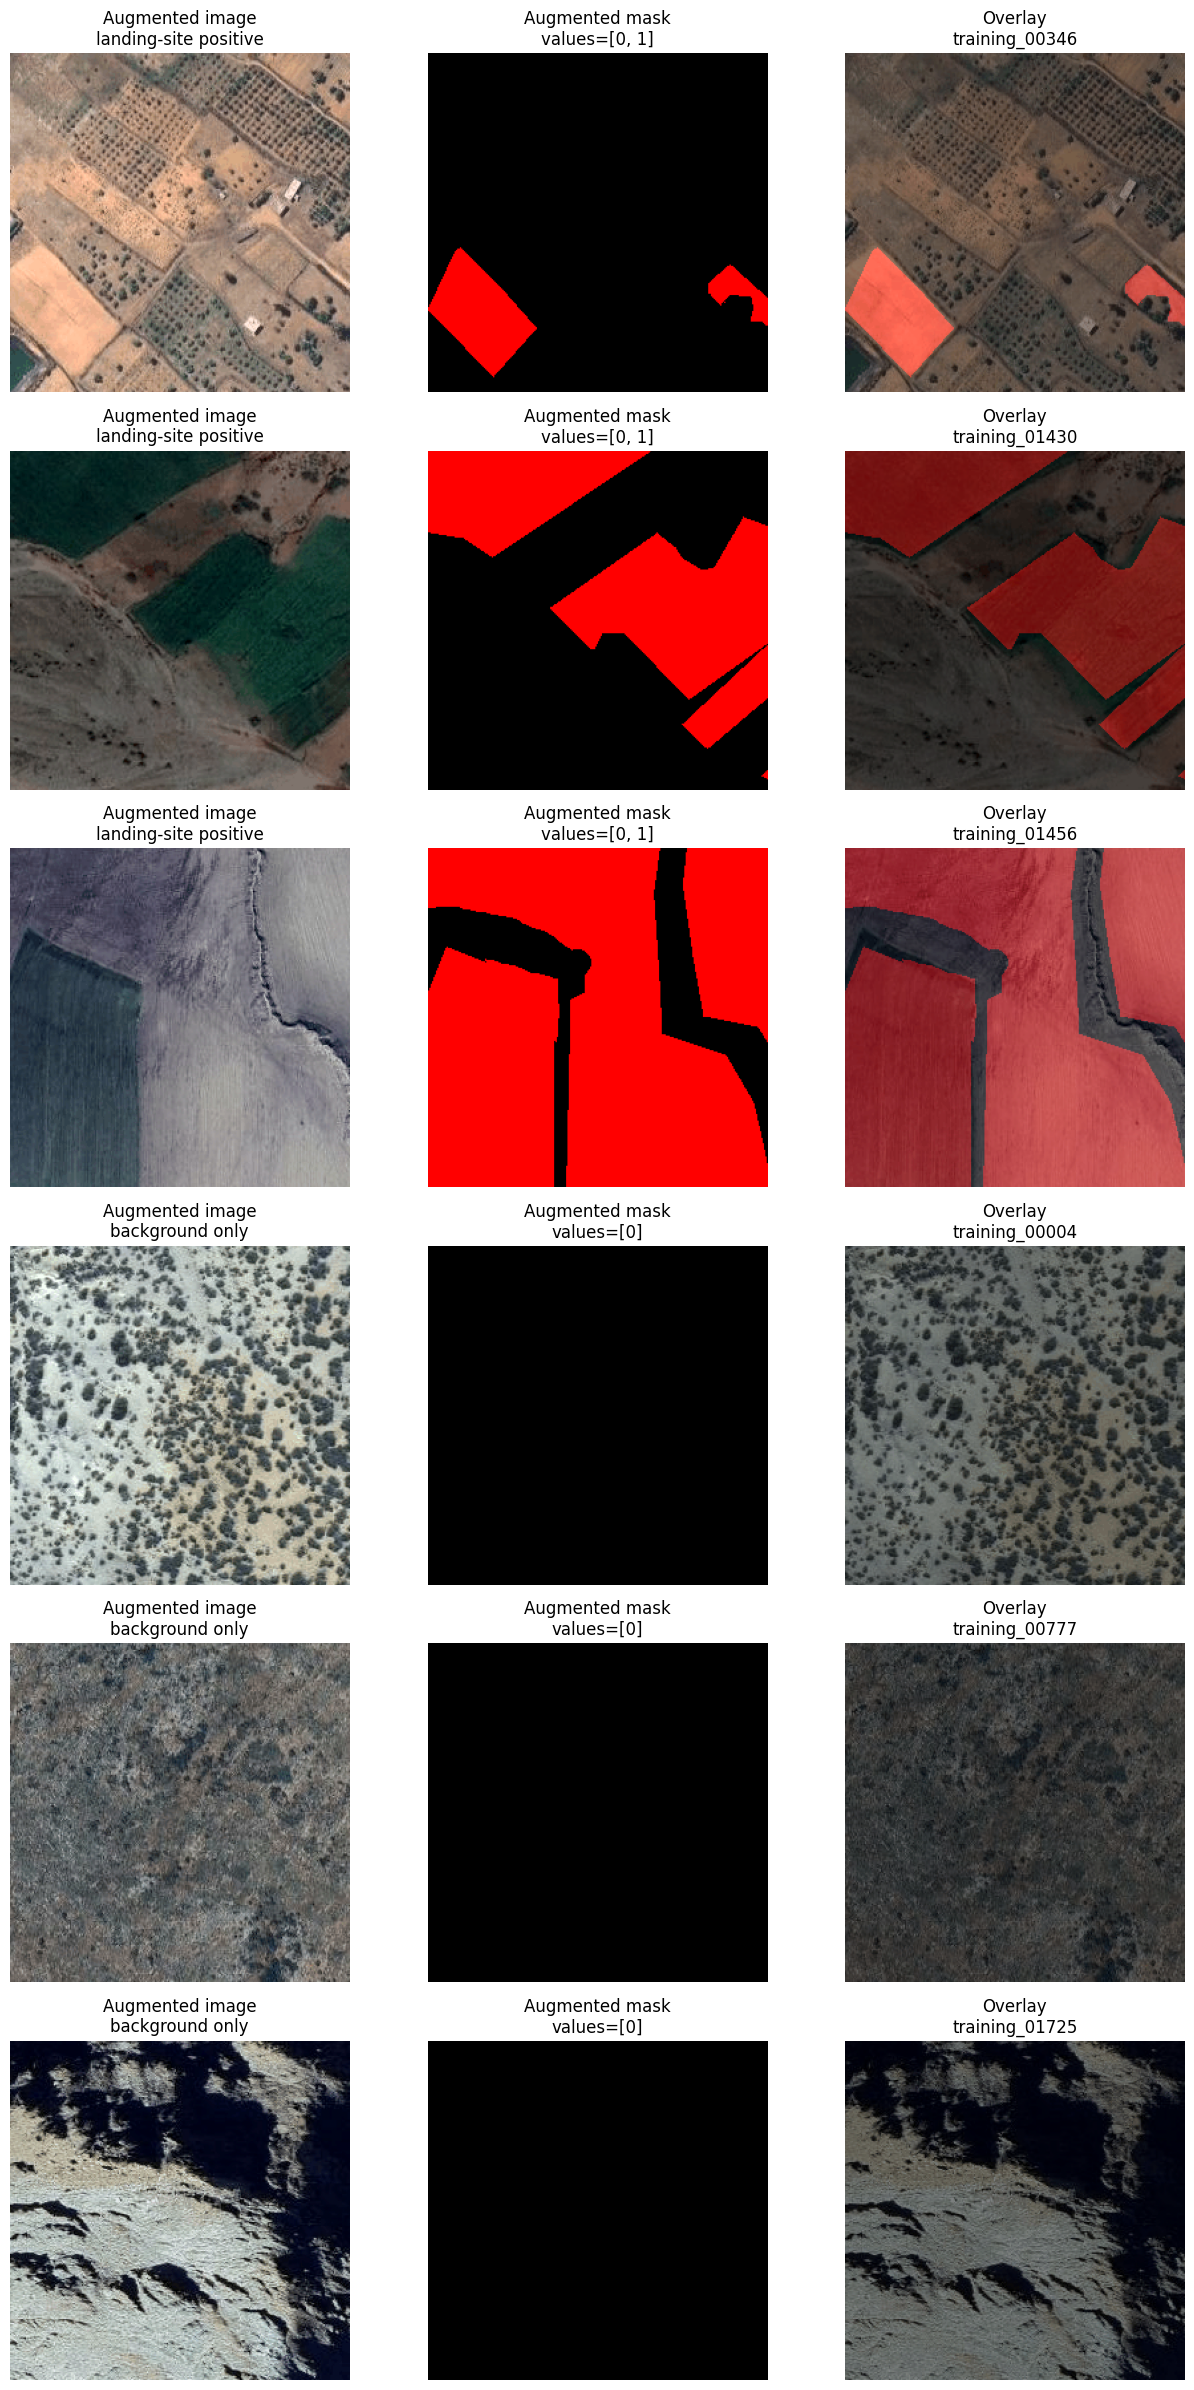

Task D passed: image and mask remain aligned.
No augmented images or masks were saved.


In [10]:
  # ============================================================
# Task D
# ============================================================

IMAGENET_MEAN_ARRAY = np.array(
    segmentation_common.IMAGENET_MEAN,
    dtype=np.float32,
)


IMAGENET_STD_ARRAY = np.array(
    segmentation_common.IMAGENET_STD,
    dtype=np.float32,
)


def denormalize_image(
    image_tensor: torch.Tensor,
) -> np.ndarray:
    """Convert a normalized tensor to a displayable image."""

    image = (
        image_tensor
        .detach()
        .cpu()
        .permute(
            1,
            2,
            0,
        )
        .numpy()
    )

    image = (
        image
        * IMAGENET_STD_ARRAY
        + IMAGENET_MEAN_ARRAY
    )

    return np.clip(
        image * 255.0,
        0,
        255,
    ).astype(np.uint8)


training_positive_pool = pairs_df[
    (
        pairs_df["split"]
        == "train"
    )
    &
    pairs_df[
        "has_landing_site"
    ]
]


training_background_pool = (
    pairs_df[
        (
            pairs_df["split"]
            == "train"
        )
        &
        (
            ~pairs_df[
                "has_landing_site"
            ]
        )
    ]
    .sort_values("image_id")
    .reset_index(drop=True)
)


positive_sanity_examples = (
    select_quantile_examples(
        training_positive_pool,
        "landing_site_fraction",
        [0.15, 0.50, 0.85],
    )
    .assign(
        example_type=(
            "landing-site positive"
        )
    )
)


background_sanity_indices = np.linspace(
    0,
    len(
        training_background_pool
    ) - 1,
    num=3,
    dtype=int,
)


background_sanity_examples = (
    training_background_pool.iloc[
        np.unique(
            background_sanity_indices
        )
    ]
    .assign(
        example_type=(
            "background only"
        )
    )
)


sanity_df = pd.concat(
    [
        positive_sanity_examples,
        background_sanity_examples,
    ],
    ignore_index=True,
)


if len(sanity_df) < 6:
    raise RuntimeError(
        "Task D requires at least six "
        "training examples."
    )


figure, axes = plt.subplots(
    len(sanity_df),
    3,
    figsize=(
        13,
        4 * len(sanity_df),
    ),
)


for row_index, row in (
    sanity_df.iterrows()
):
    with Image.open(
        row["image_path"]
    ) as image_file:
        original_image = np.asarray(
            image_file.convert("RGB"),
            dtype=np.uint8,
        )

    encoded_mask = load_mask(
        OUTPUT_ROOT
        / row[
            "encoded_mask_relpath"
        ]
    )

    # Exact same transformation object reported above.
    transformed = train_transform(
        image=original_image,
        mask=encoded_mask,
    )

    augmented_image = (
        denormalize_image(
            transformed["image"]
        )
    )

    augmented_mask = (
        transformed["mask"]
        .detach()
        .cpu()
        .numpy()
        .astype(np.uint8)
    )


    assert (
        augmented_image.shape[:2]
        == augmented_mask.shape
    )


    assert set(
        np.unique(
            augmented_mask
        ).tolist()
    ).issubset(
        {0, 1}
    )


    axes[row_index, 0].imshow(
        augmented_image
    )

    axes[row_index, 0].set_title(
        "Augmented image\n"
        f"{row['example_type']}"
    )


    axes[row_index, 1].imshow(
        colorize_mask(
            augmented_mask
        )
    )

    axes[row_index, 1].set_title(
        "Augmented mask\n"
        f"values={np.unique(augmented_mask).tolist()}"
    )


    axes[row_index, 2].imshow(
        overlay_image_mask(
            augmented_image,
            augmented_mask,
        )
    )

    axes[row_index, 2].set_title(
        "Overlay\n"
        f"{row['image_id']}"
    )


    for column_index in range(3):
        axes[
            row_index,
            column_index,
        ].axis("off")


plt.tight_layout()
plt.show()


print(
    "Task D passed: image and mask remain aligned."
)

print(
    "No augmented images or masks were saved."
)

In [11]:
# ============================================================
# Fixed comparison samples for NB1-NB3
# ============================================================

test_positive_pool = pairs_df[
    (
        pairs_df["split"]
        == "test"
    )
    &
    pairs_df[
        "has_landing_site"
    ]
]


test_background_pool = (
    pairs_df[
        (
            pairs_df["split"]
            == "test"
        )
        &
        (
            ~pairs_df[
                "has_landing_site"
            ]
        )
    ]
    .sort_values("image_id")
    .reset_index(drop=True)
)


comparison_sample_ids = []


if not test_positive_pool.empty:
    comparison_sample_ids.extend(
        select_quantile_examples(
            test_positive_pool,
            "landing_site_fraction",
            [0.10, 0.50, 0.90],
        )[
            "image_id"
        ].tolist()
    )


if not test_background_pool.empty:
    background_indices = np.linspace(
        0,
        len(
            test_background_pool
        ) - 1,
        num=min(
            2,
            len(
                test_background_pool
            ),
        ),
        dtype=int,
    )

    comparison_sample_ids.extend(
        test_background_pool.iloc[
            np.unique(
                background_indices
            )
        ][
            "image_id"
        ].tolist()
    )


# Fill to five samples if needed.
if len(comparison_sample_ids) < 5:
    remaining_test_ids = [
        image_id
        for image_id in sorted(
            pairs_df.loc[
                pairs_df["split"]
                == "test",
                "image_id",
            ].tolist()
        )
        if image_id
        not in comparison_sample_ids
    ]

    comparison_sample_ids.extend(
        remaining_test_ids[
            : 5
            - len(
                comparison_sample_ids
            )
        ]
    )


comparison_sample_ids = (
    comparison_sample_ids[:5]
)


with (
    OUTPUT_ROOT
    / "comparison_sample_ids.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        {
            "seed": SEED,

            "purpose": (
                "Use the same held-out test samples "
                "for qualitative comparison in NB1-NB3."
            ),

            "sample_ids": (
                comparison_sample_ids
            ),
        },
        file,
        indent=2,
    )


# ============================================================
# Class information
# ============================================================

class_info = {
    "num_classes": 2,

    "class_names": {
        "0": "background",
        "1": "landing_site",
    },

    "original_mask_format": (
        "RGB PNG"
    ),

    "original_rgb_to_class": {
        "0,0,0": 0,
        "255,255,255": 1,
    },

    "encoded_mask_format": (
        "single-channel uint8 PNG"
    ),

    "encoded_values": {
        "0": "background",
        "1": "landing_site",
    },

    "visualization_colors": {
        "0": [0, 0, 0],
        "1": [255, 0, 0],
    },

    "image_size": [
        IMAGE_SIZE,
        IMAGE_SIZE,
    ],

    "training_class_weights": {
        "formula": (
            "total_training_pixels / "
            "(number_of_classes * class_training_pixels)"
        ),

        "values": {
            "0": float(
                class_weights[0]
            ),

            "1": float(
                class_weights[1]
            ),
        },
    },
}


with (
    METADATA_DIR
    / "class_info.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        class_info,
        file,
        indent=2,
    )


# ============================================================
# Complete preprocessing configuration
# ============================================================

preprocessing_config = {
    "seed": SEED,

    "dataset": {
        "name": (
            "Moroccan Aircraft Emergency Landing Sites "
            "Semantic Segmentation Dataset"
        ),

        "version": 2,
        "total_pairs": 2090,
        "official_training_pairs": 1730,
        "official_testing_pairs": 360,

        "resolution": [
            IMAGE_SIZE,
            IMAGE_SIZE,
        ],
    },

    "split": {
        "strategy": (
            "Preserve the official test directory and "
            "split the official training directory into "
            "training and validation subsets."
        ),

        "stratification": (
            "Whether the mask contains landing-site pixels."
        ),

        "group_aware": True,

        "counts": expected_counts,

        "percentages": {
            "train": (
                100 * 1416 / 2090
            ),

            "val": (
                100 * 314 / 2090
            ),

            "test": (
                100 * 360 / 2090
            ),
        },
    },

    "quality_checks": {
        row["check"]: int(
            row["problem_count"]
        )
        for _, row in (
            quality_summary.iterrows()
        )
    },

    "duplicate_investigation": {
        "all_filenames_numeric": (
            all_filenames_numeric
        ),

        "exact_image_file_groups": (
            len(
                exact_image_file_groups
            )
        ),

        "exact_decoded_image_groups": (
            len(
                exact_image_pixel_groups
            )
        ),

        "exact_mask_file_groups": (
            len(
                exact_mask_file_groups
            )
        ),

        "near_duplicate_pairs": (
            len(
                near_duplicate_df
            )
        ),

        "crop_relation_pairs": (
            len(
                crop_relation_df
            )
        ),

        "multi_image_groups": (
            multi_image_group_count
        ),

        "grouping_conclusion": (
            grouping_conclusion
        ),

        "phash_threshold": (
            PHASH_THRESHOLD
        ),

        "ssim_threshold": (
            SSIM_THRESHOLD
        ),

        "orb_min_good_matches": (
            MIN_GOOD_MATCHES
        ),

        "orb_min_homography_inliers": (
            MIN_HOMOGRAPHY_INLIERS
        ),

        "orb_min_inlier_ratio": (
            MIN_INLIER_RATIO
        ),

        "orb_min_coverage": (
            MIN_COVERAGE
        ),
    },

    "mask_encoding": {
        "input": (
            "RGB PNG: black=0, white=1"
        ),

        "output": (
            "single-channel uint8 PNG "
            "with values 0 and 1"
        ),
    },

    "augmentation": {
        "training_only": True,
        "generated_dynamically": True,
        "augmented_files_saved": False,

        "pipeline": (
            augmentation_report_df
            .to_dict(
                orient="records"
            )
        ),
    },

    "normalization": {
        "mean": list(
            segmentation_common
            .IMAGENET_MEAN
        ),

        "std": list(
            segmentation_common
            .IMAGENET_STD
        ),
    },

    "class_weight_source": (
        "training pixels only"
    ),
}


with (
    METADATA_DIR
    / "preprocessing_config.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        preprocessing_config,
        file,
        indent=2,
    )


print(
    "Metadata and comparison sample IDs saved."
)

print(
    "Comparison sample IDs:",
    comparison_sample_ids,
)

Metadata and comparison sample IDs saved.
Comparison sample IDs: ['testing_00004', 'testing_00086', 'testing_00058', 'testing_00006', 'testing_00352']


In [12]:
required_artifacts = [
    SPLIT_DIR
    / "all_splits.csv",

    METADATA_DIR
    / "class_info.json",

    METADATA_DIR
    / "preprocessing_config.json",

    METADATA_DIR
    / "training_class_distribution.csv",

    COMMON_DIR
    / "segmentation_common.py",

    OUTPUT_ROOT
    / "comparison_sample_ids.json",
]


for artifact_path in (
    required_artifacts
):
    if not artifact_path.exists():
        raise FileNotFoundError(
            "Missing required artifact: "
            f"{artifact_path}"
        )


# ============================================================
# Verify manifest
# ============================================================

saved_manifest = pd.read_csv(
    SPLIT_DIR
    / "all_splits.csv"
)


assert len(saved_manifest) == 2090

assert saved_manifest[
    "image_id"
].is_unique


# Paths must be portable relative paths.
assert not saved_manifest[
    "image_relpath"
].str.startswith("/").any()


assert not saved_manifest[
    "encoded_mask_relpath"
].str.startswith("/").any()


assert (
    saved_manifest[
        "split"
    ]
    .value_counts()
    .to_dict()
    == expected_counts
)


assert (
    saved_manifest.groupby(
        "group_id"
    )["split"]
    .nunique()
    .max()
    == 1
)


# ============================================================
# Verify all encoded masks
# ============================================================

encoded_mask_paths = list(
    ENCODED_MASK_DIR.rglob(
        "*.png"
    )
)


assert (
    len(encoded_mask_paths)
    == 2090
)


invalid_encoded_masks = []


for encoded_mask_path in (
    encoded_mask_paths
):
    with Image.open(
        encoded_mask_path
    ) as mask_file:
        encoded_mask = np.asarray(
            mask_file
        )

    if encoded_mask.ndim != 2:
        invalid_encoded_masks.append(
            {
                "path": str(
                    encoded_mask_path
                ),

                "problem": (
                    f"Expected single-channel mask, "
                    f"received shape {encoded_mask.shape}"
                ),
            }
        )

        continue

    unique_values = set(
        np.unique(
            encoded_mask
        ).tolist()
    )

    if not unique_values.issubset(
        {0, 1}
    ):
        invalid_encoded_masks.append(
            {
                "path": str(
                    encoded_mask_path
                ),

                "problem": (
                    f"Invalid values: "
                    f"{sorted(unique_values)}"
                ),
            }
        )


if invalid_encoded_masks:
    display(
        pd.DataFrame(
            invalid_encoded_masks
        )
    )

    raise RuntimeError(
        "One or more encoded masks are invalid."
    )


# ============================================================
# Final output structure
# ============================================================

print("NB0_outputs/")
print("├── splits/")
print("│   └── all_splits.csv")
print("├── encoded_masks/")
print("│   ├── training/")
print("│   └── testing/")
print("├── metadata/")
print("│   ├── class_info.json")
print("│   ├── preprocessing_config.json")
print("│   └── training_class_distribution.csv")
print("├── common/")
print("│   └── segmentation_common.py")
print("└── comparison_sample_ids.json")


print("\nFinal split counts:")

display(
    saved_manifest[
        "split"
    ]
    .value_counts()
    .reindex(
        [
            "train",
            "val",
            "test",
        ]
    )
)


print("\nFinal checks passed:")

print("✓ 2,090 valid image-mask pairs")
print("✓ Original RGB mask format documented")
print("✓ Corrupted files checked")
print("✓ Images without masks checked")
print("✓ Masks without images checked")
print("✓ Dimension mismatches checked")
print("✓ Unknown mask colours checked")
print("✓ Exact duplicate files checked")
print("✓ Near-duplicate images checked")
print("✓ Crop/same-scene relations investigated")
print("✓ Related images grouped before splitting")
print("✓ Official test directory preserved")
print("✓ Train = 1,416")
print("✓ Validation = 314")
print("✓ Test = 360")
print("✓ No group or duplicate crosses splits")
print("✓ Manifest contains relative paths")
print("✓ Encoded masks contain only 0 and 1")
print("✓ Class weights use training pixels only")
print("✓ One training augmentation pipeline used")
print("✓ Six Task D examples displayed")
print("✓ No augmented images were saved")
print("✓ Shared reusable module exported")

print("\nNB0 completed successfully.")

NB0_outputs/
├── splits/
│   └── all_splits.csv
├── encoded_masks/
│   ├── training/
│   └── testing/
├── metadata/
│   ├── class_info.json
│   ├── preprocessing_config.json
│   └── training_class_distribution.csv
├── common/
│   └── segmentation_common.py
└── comparison_sample_ids.json

Final split counts:


split
train    1416
val       314
test      360
Name: count, dtype: int64


Final checks passed:
✓ 2,090 valid image-mask pairs
✓ Original RGB mask format documented
✓ Corrupted files checked
✓ Images without masks checked
✓ Masks without images checked
✓ Dimension mismatches checked
✓ Unknown mask colours checked
✓ Exact duplicate files checked
✓ Near-duplicate images checked
✓ Crop/same-scene relations investigated
✓ Related images grouped before splitting
✓ Official test directory preserved
✓ Train = 1,416
✓ Validation = 314
✓ Test = 360
✓ No group or duplicate crosses splits
✓ Manifest contains relative paths
✓ Encoded masks contain only 0 and 1
✓ Class weights use training pixels only
✓ One training augmentation pipeline used
✓ Six Task D examples displayed
✓ No augmented images were saved
✓ Shared reusable module exported

NB0 completed successfully.
